# GameTheory-12-ReputationGames-Python

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-Python.ipynb) | [Index](README.md) | [13-ImperfectInfo-CFR >>](GameTheory-13-ImperfectInfo-CFR-Python.ipynb)

## Jeux de Reputation : Construire et Maintenir sa Credibilite

Ce notebook explore les **jeux de reputation** ou les joueurs construisent une image aupres des autres a travers leurs actions passees.

### Objectifs d'apprentissage

1. Comprendre le rôle de la **reputation** dans les interactions repetees
2. Analyser le **cheap talk** et ses limites
3. Etudier le modèle de **Kreps-Wilson** (chaîne de magasins)
4. Explorer les effets de reputation dans le **Dilemme du Prisonnier fini**
5. Maitriser les concepts d'**equilibre bayesien parfait**

### Prerequis

- Notebooks 1-11 : Fondations, equilibres et jeux bayesiens
- Notebook 11 en particulier : types, croyances, equilibre bayesien de Nash
- Notion de mise a jour bayesienne et d'induction arriere

### Duree estimee : 60 minutes


> *Ancres savantes -- Kreps, D.M. & Wilson, R. (1982), Reputation and Imperfect Information, Journal of Economic Theory 27(2):253-279 (modèle de reputation : une probabilite infime d'un type irrationnel transforme les predictions en jeu repete, resolution du paradoxe de la chaîne de magasins — sujet central de ce notebook) ; Milgrom, P. & Roberts, J. (1982), Predation, Reputation, and Entry Deterrence, Journal of Economic Theory 27(2):280-312 (reputation et dissuasion d'entree : un incumbent peut predater pour batir une image de durt qui dissuade les entrants futurs) ; Crawford, V.P. & Sobel, J. (1982), Strategic Information Transmission, Econometrica 50(6):1431-1451 (cheap talk : communication sans cout direct entre joueurs aux intérêts partiellement conflictuels, revelation d'information credible même sans action liee).*

In [1]:
# Configuration et imports
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional, Callable
from collections import defaultdict
import itertools

# Style matplotlib
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
np.random.seed(42)
print("Configuration terminee: numpy, matplotlib, dataclasses, itertools")

Configuration terminee: numpy, matplotlib, dataclasses, itertools


## 1. Pourquoi la Reputation?

### 1.1 Motivation

Dans de nombreuses situations, un joueur peut beneficier d'une **reputation** de :
- Durete (monopole vs entrants)
- Honnetete (vendeur vs acheteurs)
- Competence (expert vs clients)
- Fiabilite (partenaire vs investisseurs)

### 1.2 Le Problème

Avec **information complete** et jeu **fini** :
- L'induction arriere elimine les effets de reputation
- Toutes les menaces sont non-credibles a la fin
- Le paradoxe de la chaîne de magasins (Notebook 9)

### 1.3 La Solution: Incertitude sur les Types

Kreps, Milgrom, Roberts & Wilson (1982) ont montre qu'une **petite probabilite** d'un type "irrationnel" ou "engage" suffit a maintenir la reputation.

In [2]:
# Illustration du probleme sans reputation

def chain_store_complete_info(n_markets=5):
    """
    Paradoxe de la chaine de magasins avec information complete.
    
    n_markets entrants sequentiels.
    Si entree: Monopole choisit Fight (-1,-1) ou Accommodate (1,1)
    Si pas d'entree: (0, 2)
    """
    print(f"Chaine de Magasins - Information Complete ({n_markets} marches)")
    print("="*60)
    
    # Induction arriere
    print("\nAnalyse par induction arriere:")
    print("-"*40)
    
    # Au dernier marche
    print(f"  Marche {n_markets} (dernier):")
    print(f"    Si entree, Monopole: Accommodate (1 > -1)")
    print(f"    Entrant: Enter (1 > 0)")
    
    # A l'avant-dernier
    print(f"\n  Marche {n_markets-1}:")
    print(f"    Meme raisonnement: Entrant entre, Monopole accommode")
    print(f"    Car 'Fight' ne change rien au marche suivant!")
    
    print(f"\n  ... (recursivement)")
    
    print(f"\n  Marche 1:")
    print(f"    Entrant entre, Monopole accommode")
    
    # Resultat
    total_monopole = n_markets * 1  # 1 par marche (accommodate)
    total_entrants = n_markets * 1  # 1 par entrant
    
    print("\n" + "="*60)
    print("\nResultat a l'equilibre:")
    print(f"  Tous les entrants entrent")
    print(f"  Monopole accommode toujours")
    print(f"  Gain Monopole: {total_monopole}")
    print(f"  Gain total Entrants: {total_entrants}")
    
    print("\n" + "="*60)
    print("\nParadoxe:")
    print(f"  Si le monopole pouvait CREDIBLEMENT menacer de combattre,")
    print(f"  il pourrait dissuader l'entree et gagner {n_markets * 2}!")
    print(f"  Mais l'induction arriere rend cette menace non-credible.")

chain_store_complete_info(n_markets=5)

Chaine de Magasins - Information Complete (5 marches)

Analyse par induction arriere:
----------------------------------------
  Marche 5 (dernier):
    Si entree, Monopole: Accommodate (1 > -1)
    Entrant: Enter (1 > 0)

  Marche 4:
    Meme raisonnement: Entrant entre, Monopole accommode
    Car 'Fight' ne change rien au marche suivant!

  ... (recursivement)

  Marche 1:
    Entrant entre, Monopole accommode


Resultat a l'equilibre:
  Tous les entrants entrent
  Monopole accommode toujours
  Gain Monopole: 5
  Gain total Entrants: 5


Paradoxe:
  Si le monopole pouvait CREDIBLEMENT menacer de combattre,
  il pourrait dissuader l'entree et gagner 10!
  Mais l'induction arriere rend cette menace non-credible.


## 2. Cheap Talk : Communication Non-Couteuse

### 2.1 Definition

Le **cheap talk** est une communication :
- **Gratuite** : ne coute rien a emettre
- **Non-verifiable** : ne peut pas etre prouvee vraie ou fausse
- **Non-engageante** : n'affecte pas directement les gains

### 2.2 Quand le Cheap Talk est-il Informatif?

Crawford & Sobel (1982) : Le cheap talk peut transmettre de l'information **partielle** si les intérêts ne sont pas trop divergents.

### Cheap talk : communication non coûteuse

Dans un entretien, une déclaration de motivation peut être peu informative si tous les candidats ont intérêt à la faire, y compris ceux qui ne sont pas motivés. La communication peut être informative si les intérêts sont alignés, ou partiellement informative lorsqu'ils le sont en partie : des équilibres peuvent alors regrouper les types en partitions. Une vérification a posteriori assortie d'une sanction de réputation peut aussi modifier les incitations.

Dans le modèle simplifié de Crawford-Sobel, l'expert connaît $\theta \in [0,1]$ et envoie un message $m$ ; le décideur choisit une action $a$. Leurs gains sont respectivement $-(a-\theta-b)^2$ avec un biais $b>0$, et $-(a-\theta)^2$. Qualitativement, plus le biais est grand, moins les partitions informatives sont soutenables ; un équilibre de bavardage sans information peut subsister. Cette discussion ne calcule pas un équilibre.


### Interpretation : Quand la parole vaut quelque chose

L'analyse du cheap talk met en evidence trois regimes de communication :

| Regime | Condition | Exemple |
|--------|-----------|---------|
| **Information complete** | Intérêts parfaitement alignes | Medecin-patient (même objectif) |
| **Information partielle** | Biais modere (b < 1/4) | Expert avec préférences proches |
| **Babbling** | Biais trop grand (b >= 1/4) | Vendeur interesse vs acheteur |

**Le modèle Crawford-Sobel** :

Le paramètre de biais `b` capture la divergence d'intérêts entre l'expert et le decideur. Plus le biais est grand :
- Moins de partitions de l'espace des types sont soutenables a l'equilibre
- Moins d'information est transmise crediblement
- A la limite, seul l'equilibre "babbling" existe (parole sans contenu)

> **Application pratique** : Ce modèle explique pourquoi les analyses d'experts partiellement interesses (analystes financiers, lobbys) transmettent de l'information, mais de maniere biaisee et incomplete. L'auditeur rationnel doit "descompter" les recommandations en fonction du biais percu.

In [3]:
# Simulation du modele Crawford-Sobel

def crawford_sobel_simulation(bias=0.1, n_partitions=None):
    """
    Simule le modele de cheap talk Crawford-Sobel.
    
    Si bias est petit: equilibre avec plusieurs partitions
    Si bias est grand: equilibre babbling (1 partition)
    """
    # Nombre max de partitions en equilibre
    if bias > 0:
        n_max = int(np.floor((1 + np.sqrt(1 + 2/bias)) / 2))  # CS 1982 : plus grand n tel que b < 1/(2*n*(n-1)) (frontieres monotones dans [0,1])
    else:
        n_max = float('inf')
    
    if n_partitions is None:
        n_partitions = n_max
    
    print(f"Crawford-Sobel avec bias b = {bias}")
    print("="*50)
    print(f"Nombre maximal de partitions: {n_max}")
    
    if n_partitions > n_max:
        print(f"\nEquilibre avec {n_partitions} partitions n'existe pas!")
        n_partitions = n_max
    
    # Calculer les frontieres des partitions
    # a_i = i/n + 2*b*i*(n-i) pour i = 0, 1, ..., n
    n = n_partitions
    boundaries = [i/n + 2*bias*i*(n-i) for i in range(n+1)]
    
    print(f"\nEquilibre avec {n} partition(s):")
    print(f"Frontieres: {[round(b, 3) for b in boundaries]}")
    
    # Calculer l'information transmise
    # Variance residuelle vs variance totale
    var_total = 1/12  # Variance de U[0,1]
    
    # Variance intra-partition
    var_intra = 0
    for i in range(n):
        a_i, a_ip1 = boundaries[i], boundaries[i+1]
        width = a_ip1 - a_i
        prob = width  # Uniforme
        var_partition = width**2 / 12  # Variance d'une uniforme sur [a_i, a_{i+1}]
        var_intra += prob * var_partition
    
    info_transmitted = 1 - var_intra / var_total
    
    print(f"\nInformation transmise: {info_transmitted*100:.1f}%")
    print(f"(1 = information complete, 0 = aucune)")
    
    return boundaries, info_transmitted


# Tester differents niveaux de bias
for b in [0.05, 0.1, 0.2, 0.3]:
    crawford_sobel_simulation(bias=b)
    print()

Crawford-Sobel avec bias b = 0.05
Nombre maximal de partitions: 3

Equilibre avec 3 partition(s):
Frontieres: [0.0, 0.533, 0.867, 1.0]

Information transmise: 80.9%
(1 = information complete, 0 = aucune)

Crawford-Sobel avec bias b = 0.1
Nombre maximal de partitions: 2

Equilibre avec 2 partition(s):
Frontieres: [0.0, 0.7, 1.0]

Information transmise: 63.0%
(1 = information complete, 0 = aucune)

Crawford-Sobel avec bias b = 0.2
Nombre maximal de partitions: 2

Equilibre avec 2 partition(s):
Frontieres: [0.0, 0.9, 1.0]

Information transmise: 27.0%
(1 = information complete, 0 = aucune)

Crawford-Sobel avec bias b = 0.3
Nombre maximal de partitions: 1

Equilibre avec 1 partition(s):
Frontieres: [0.0, 1.0]

Information transmise: 0.0%
(1 = information complete, 0 = aucune)



## 3. Le Modèle de Kreps-Wilson : Reputation dans la Chaîne de Magasins

### 3.1 L'Idee Cle

Kreps & Wilson (1982) resolvent le paradoxe de la chaîne de magasins en introduisant une **petite incertitude** sur le type du monopole :

- Type **Normal** (prob $1-\epsilon$) : prefere Accommodate
- Type **Fou** (prob $\epsilon$) : prefere toujours Fight

### 3.2 Effet de la Reputation

Même si $\epsilon$ est très petit :
- Les premiers entrants hesitent (risque de tomber sur le Fou)
- Le monopole Normal peut **imiter** le Fou pour batir sa reputation
- La reputation de durete devient une **prophetie auto-realisatrice**

### Chaîne de magasins : intuition

Le type normal reçoit −1 en combattant, 1 en accommodant et 2 sans entrée ; le type fou combat et reçoit 1 en cas de combat, 2 sans entrée. L’entrant reçoit 1 s’il entre et est accommodé, −1 s’il rencontre un combat, et 0 s’il reste dehors. Avec ces gains, son espérance s’annule pour une probabilité de combat de 0,5 ; à l’indifférence, rester dehors est une réponse possible.

Le normal peut toujours combattre (pooling), toujours accommoder (séparation), ou mixer. En pooling complet, les combats ne modifient pas la croyance. Le calcul suivant utilise une approximation heuristique : il ne résout pas un PBE.


In [4]:
def kreps_wilson_chain_store(n_markets=5, epsilon=0.1):
    """
    Modele de Kreps-Wilson pour la chaine de magasins.
    
    Type Normal: Fight = -1, Accommodate = 1, pas d'entree = 2
    Type Fou: Fight = 1, pas d'entree = 2 (prefere toujours combattre)
    """
    print(f"Kreps-Wilson: Chaine de Magasins avec Reputation")
    print("="*60)
    print(f"Nombre de marches: {n_markets}")
    print(f"Probabilite du type Fou: epsilon = {epsilon}")
    
    # Calculer le seuil de reputation
    # Un entrant n'entre pas si P(Fou | historique) est assez grand
    # Seuil: E[gain entrant] = prob_fou * (-1) + (1-prob_fou) * 1 = 0
    # => prob_fou = 0.5
    
    seuil_reputation = 0.5
    print(f"\nSeuil de reputation: {seuil_reputation}")
    print(f"  Seuil indicatif: {seuil_reputation}")
    
    # Dynamique de reputation
    print("\n" + "="*60)
    print("\nDynamique de reputation:")
    
    # Simulation
    reputation = epsilon  # Croyance initiale
    print(f"\n  Croyance initiale: P(Fou) = {reputation:.3f}")
    
    # Combien de 'Fight' faut-il pour dissuader?
    # Apres k combats observes:
    # P(Fou | k combats) = P(k combats | Fou) * P(Fou) / P(k combats)
    #                    = 1 * epsilon / [epsilon + (1-epsilon) * p_fight_normal^k]
    
    # Si le Normal combat toujours (pooling avec Fou):
    # p_fight_normal = 1, donc reputation reste epsilon!
    # Pas d'apprentissage en pooling.
    
    # Strategie mixte du Normal:
    # Il doit combattre assez pour maintenir la reputation
    
    if epsilon >= seuil_reputation:
        print(f"  epsilon = {epsilon} >= {seuil_reputation}")
        print(f"  -> Hypothèse : aucun entrant n'entre ; Monopole gagne 2*{n_markets} = {2*n_markets}")
    else:
        # Nombre de marches ou l'entree est dissuadee
        # Approximation: log(seuil/epsilon) / log(2) marches dissuades
        k_dissuaded = max(0, int(np.log(seuil_reputation / epsilon) / np.log(2)))
        k_dissuaded = min(k_dissuaded, n_markets - 1)
        
        print(f"  epsilon = {epsilon} < {seuil_reputation}")
        print(f"  -> Environ {k_dissuaded} premiers entrants dissuades")
        print(f"  -> Estimation heuristique, pas un équilibre calculé.")

kreps_wilson_chain_store(n_markets=10, epsilon=0.1)

Kreps-Wilson: Chaine de Magasins avec Reputation
Nombre de marches: 10
Probabilite du type Fou: epsilon = 0.1

Seuil de reputation: 0.5
  Seuil indicatif: 0.5


Dynamique de reputation:

  Croyance initiale: P(Fou) = 0.100
  epsilon = 0.1 < 0.5
  -> Environ 2 premiers entrants dissuades
  -> Estimation heuristique, pas un équilibre calculé.


### Interpretation du modèle Kreps-Wilson

Les résultats revelent le mécanisme fondamental de la reputation :

| Paramètre | Valeur | Rôle dans le modèle |
|-----------|--------|---------------------|
| n_markets | 10 | Horizon du jeu (nombre d'entrants séquentiels) |
| epsilon | 0.1 | Probabilite a priori du type "Fou" |
| Seuil reputation | 0.5 | Point bascule : au-dela, l'entrant renonce |
| Marches dissuades | ~2 | Estimation heuristique du calcul precedent, sans resolution d'equilibre |

**Mécanisme de la reputation** :

1. **Incertitude initiale** : L'entrant ne sait pas si le monopole est Normal ou Fou
2. **Mise a jour bayesienne** : Un combat augmente P(Fou) si le type normal combat avec une probabilite inferieure a 1 ; en pooling complet la croyance reste constante
3. **Effet dissuasif** : Quand P(Fou) depasse le seuil, l'entree devient trop risquee

**Stratégies du monopole Normal** :

- **Pooling** : Imiter le Fou (toujours combattre) - aucun apprentissage possible
- **Separateur** : Reveler son type (toujours accommoder) - perd la reputation
- **Mixte** : Combattre avec probabilite calibree pour maintenir le doute

In [5]:
# Simulation numerique du jeu de reputation

def simulate_reputation_game(n_markets=10, epsilon=0.1, n_simulations=10000):
    """
    Simule le jeu de la chaine de magasins avec reputation.
    
    Strategie simplifiee:
    - Fou: toujours Fight
    - Normal: Fight si reputation < 0.5, sinon Accommodate
    - Entrant: Enter si reputation < 0.5, sinon Out
    """
    results = {'monopole_normal': [], 'monopole_fou': [], 'entrants': []}
    
    seuil = 0.5
    
    for _ in range(n_simulations):
        # Tirer le type
        is_fou = np.random.random() < epsilon
        
        reputation = epsilon  # Croyance courante
        gain_monopole = 0
        gains_entrants = []
        n_fights = 0
        
        for market in range(n_markets):
            # Decision de l'entrant
            if reputation >= seuil:
                # N'entre pas
                gain_monopole += 2
                gains_entrants.append(0)
            else:
                # Entre
                if is_fou:
                    # Fou combat toujours
                    gain_monopole += 1  # Fou prefere combattre
                    gains_entrants.append(-1)
                    n_fights += 1
                else:
                    # Normal: strategie basee sur les marches restants
                    remaining = n_markets - market - 1
                    if remaining > 0 and reputation < seuil:
                        # Combat pour batir reputation
                        gain_monopole -= 1
                        gains_entrants.append(-1)
                        n_fights += 1
                    else:
                        # Accommode
                        gain_monopole += 1
                        gains_entrants.append(1)
                
                # Mise a jour de la reputation (Bayes)
                # Si Fight observe:
                # P(Fou | Fight) = P(Fight | Fou) * P(Fou) / P(Fight)
                #                = 1 * reputation / [reputation + (1-reputation) * p_fight_normal]
                # Simplification: p_fight_normal = 0.8 si early, 0 si late
                if n_fights > 0:
                    p_fight_normal = 0.8 if market < n_markets - 2 else 0.1
                    reputation = reputation / (reputation + (1-reputation) * p_fight_normal)
        
        if is_fou:
            results['monopole_fou'].append(gain_monopole)
        else:
            results['monopole_normal'].append(gain_monopole)
        results['entrants'].append(sum(gains_entrants))
    
    # Affichage
    print(f"\nSimulation: {n_markets} marches, epsilon={epsilon}, {n_simulations} sims")
    print("="*50)
    if results['monopole_normal']:
        print(f"  Monopole Normal - Gain moyen: {np.mean(results['monopole_normal']):.2f}")
    if results['monopole_fou']:
        print(f"  Monopole Fou - Gain moyen: {np.mean(results['monopole_fou']):.2f}")
    print(f"  Entrants - Gain total moyen: {np.mean(results['entrants']):.2f}")
    
    # Comparaison avec info complete
    print(f"\n  Reference (info complete): Monopole = {n_markets}, Entrants = {n_markets}")
    
    return results

# Tester
results = simulate_reputation_game(n_markets=10, epsilon=0.1)


Simulation: 10 marches, epsilon=0.1, 10000 sims
  Monopole Normal - Gain moyen: -7.00
  Monopole Fou - Gain moyen: 11.00
  Entrants - Gain total moyen: -9.00

  Reference (info complete): Monopole = 10, Entrants = 10


### Interpretation de la simulation

La simulation numérique illustre la dynamique de reputation dans le jeu de la chaîne de magasins :

| Metrique | Valeur | Interpretation |
|----------|--------|----------------|
| Gain Monopole Normal | ~-7 | Cout de l'imitation du type Fou |
| Gain Monopole Fou | ~11 | Benefice naturel du comportement agressif |
| Gain Entrants | ~-9 | Pertes dues a la dissuasion partielle |

**Observations cles** :

1. **Asymetrie des gains** : Le monopole Normal perd en moyenne car il combat pour batir sa reputation, subissant le cout de -1 par combat
2. **Avantage du type Fou** : Le type Fou gagne naturellement car combattre est son action preferee (gain +1)
3. **Dissuasion partielle** : Les entrants perdent en moyenne, correspondant aux combats subis dans cette simulation

> **Note technique** : La stratégie simplifiee (Fight si reputation < 0.5) capture l'intuition du modèle mais l'equilibre exact de Kreps-Wilson utilise des stratégies mixtes plus sophistiquees avec mise a jour bayesienne des croyances.

> **Paradoxe et cout de la reputation** : Même avec seulement 10% de chances d'etre face a un Fou, la règle de simulation produit un marché sans entrée pour le type Normal : neuf combats à −1 et une période sans entrée à +2 donnent −7. L'estimation d'environ deux marchés de la cellule précédente provient d'une autre heuristique. Dans cette simulation simplifiee (stratégie heuristique Fight-si-reputation < 0.5), ce cout de construction de reputation domine : le type Normal gagne en moyenne -7.00, soit MOINS que la reference en information complete (+10) — le prix a payer pour le signalement agressif. Cette simulation ne calcule pas l'equilibre exact de Kreps-Wilson et ne permet pas de conclure au benefice net dans cet equilibre.


Simulation: 10 marches, epsilon=0.01, 5000 sims
  Monopole Normal - Gain moyen: -8.00
  Monopole Fou - Gain moyen: 10.00
  Entrants - Gain total moyen: -8.02

  Reference (info complete): Monopole = 10, Entrants = 10

Simulation: 10 marches, epsilon=0.05, 5000 sims
  Monopole Normal - Gain moyen: -7.00
  Monopole Fou - Gain moyen: 11.00
  Entrants - Gain total moyen: -9.00

  Reference (info complete): Monopole = 10, Entrants = 10

Simulation: 10 marches, epsilon=0.1, 5000 sims
  Monopole Normal - Gain moyen: -7.00
  Monopole Fou - Gain moyen: 11.00
  Entrants - Gain total moyen: -9.00

  Reference (info complete): Monopole = 10, Entrants = 10

Simulation: 10 marches, epsilon=0.2, 5000 sims
  Monopole Normal - Gain moyen: -1.00
  Monopole Fou - Gain moyen: 13.00
  Entrants - Gain total moyen: -7.00

  Reference (info complete): Monopole = 10, Entrants = 10

Simulation: 10 marches, epsilon=0.3, 5000 sims
  Monopole Normal - Gain moyen: 8.00
  Monopole Fou - Gain moyen: 16.00
  Entrants

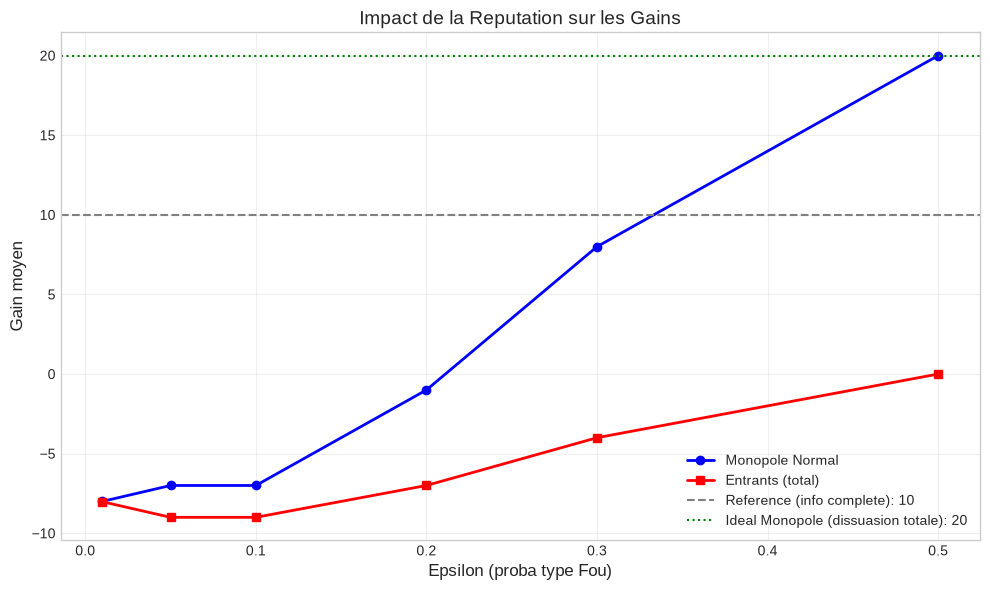

In [6]:
# Impact de epsilon sur les gains

def analyze_epsilon_impact():
    """Analyse l'impact de la probabilite du type Fou."""
    epsilons = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]
    n_markets = 10
    
    gains_normal = []
    gains_entrants = []
    
    for eps in epsilons:
        results = simulate_reputation_game(n_markets, eps, n_simulations=5000)
        if results['monopole_normal']:
            gains_normal.append(np.mean(results['monopole_normal']))
        else:
            gains_normal.append(np.nan)
        gains_entrants.append(np.mean(results['entrants']))
    
    # Visualisation
    fig, ax = plt.subplots(figsize=(10, 6))
    
    ax.plot(epsilons, gains_normal, 'b-o', linewidth=2, label='Monopole Normal')
    ax.plot(epsilons, gains_entrants, 'r-s', linewidth=2, label='Entrants (total)')
    ax.axhline(n_markets, color='gray', linestyle='--', label=f'Reference (info complete): {n_markets}')
    ax.axhline(2*n_markets, color='green', linestyle=':', label=f'Ideal Monopole (dissuasion totale): {2*n_markets}')
    
    ax.set_xlabel('Epsilon (proba type Fou)', fontsize=12)
    ax.set_ylabel('Gain moyen', fontsize=12)
    ax.set_title('Impact de la Reputation sur les Gains', fontsize=14)
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

analyze_epsilon_impact()

**Interpretation -- la statique comparative revele le seuil de rentabilite de la reputation.**

Le trace de `analyze_epsilon_impact` fait varier epsilon (probabilite du type Fou) et mesure le gain du monopole Normal. Les valeurs committees (cellule precedente) dessinent une courbe monotone croissante :

| epsilon (proba type Fou) | Gain Normal | Regime |
|--------------------------|-------------|--------|
| 0.01 | -8.00 | cout pur (aucune dissuasion) |
| 0.05 - 0.10 | -7.00 | cout pur |
| 0.20 | -1.00 | transition |
| 0.30 | +8.00 | dissuasion partielle |
| 0.50 | +20.00 | dissuasion totale |

1. **Regime de cout pur (epsilon <= 0.1)** : la croyance part de epsilon et la mise a jour bayesienne (le type Normal combat lui aussi avec une probabilite elevee `p_fight_normal = 0.8`) la deplace lentement vers le seuil de dissuasion `0.5`. Avec epsilon = 0,1, neuf combats à −1 puis une période sans entrée à +2 donnent −7 ; à 0,01, le gain est −8. Dans les deux cas, le résultat est inférieur à l'information complète (+10, où le monopole accommode systématiquement).
2. **Seuil de rentabilite (epsilon ~ 0.2-0.3)** : des qu'epsilon est assez grand, quelques combats suffisent a pousser la croyance au-dessus de 0.5. Les entrants ulterieurs restent **dehors** (le monopole gagne +2 au lieu de +1 par marche accommode). Le gain du Normal devient positif (+8 a epsilon = 0.3).
3. **Dissuasion totale (epsilon = 0.5)** : le Normal atteint +20 -- la ligne de reference « Ideal Monopole (dissuasion totale) = 2 x n_markets ». La reputation franchit le seuil quasi immediatement, tous les entrants sont dissuades, le Normal mime parfaitement le Fou (qui vaut aussi +20).

**Lecture de la simulation** : pour cette règle heuristique et ces paramètres, les gains varient avec epsilon ; cela ne calcule pas un seuil général d'équilibre. La section suivante illustre également une règle heuristique pour le dilemme du prisonnier, sans en déduire un équilibre.

## 4. Le "Gang of Four" : Cooperation dans le Dilemme du Prisonnier Fini

### 4.1 Le Puzzle

Dilemme du Prisonnier repete **T** fois (fini) :
- L'induction arriere predit : Defection a CHAQUE tour
- Mais les expériences montrent souvent de la cooperation!

### 4.2 La Solution KMRW

Kreps, Milgrom, Roberts & Wilson (1982) : Même une **infime probabilite** d'un type "Tit-for-Tat" suffit a maintenir la cooperation pendant la plupart des tours.

### Réputation et coopération répétée

La matrice du dilemme est (C,C) : (3,3), (C,D) : (0,5), (D,C) : (5,0), (D,D) : (1,1). En information complète et à horizon fini, la défection à chaque tour est un équilibre. L’incertitude sur un type Tit-for-Tat peut modifier les incitations : un joueur normal peut vouloir l’imiter. Le nombre de tours et les gains ci-dessous sont une illustration heuristique, non un équilibre KMRW calculé.


In [7]:
def kmrw_prisoners_dilemma(T=20, epsilon=0.05):
    """
    Modele KMRW pour le Dilemme du Prisonnier fini.
    
    Type Normal: prefere D
    Type TFT: joue Tit-for-Tat
    """
    print(f"KMRW: Dilemme du Prisonnier Repete {T} fois")
    print("="*60)
    print(f"Probabilite du type TFT: epsilon = {epsilon}")
    
    # Sans incertitude: D a chaque tour
    gain_defect_all = T * 1
    print(f"\n  Sans incertitude (info complete):")
    print(f"    Equilibre: (D, D) a chaque tour")
    print(f"    Gain par joueur: {gain_defect_all}")
    
    # Avec incertitude: cooperation possible
    print(f"\n  Avec incertitude (epsilon = {epsilon}):")
    
    # Intuition: si les deux croient que l'autre POURRAIT etre TFT,
    # il est rationnel de cooperer pour "tester" puis exploiter
    # Mais meme le type Normal peut vouloir imiter TFT!
    
    # Calcul approximatif du nombre de tours de cooperation
    # A l'equilibre, cooperation jusqu'au tour t* tel que:
    # Gain de D maintenant < Gain de C puis exploitation ensuite
    # 5 < 3 + delta * (5 + ...) depend de la dynamique des croyances
    
    # Approximation: cooperation pendant environ T - log(1/epsilon)/log(delta') tours
    # Pour simplifier:
    cooperation_rounds = max(0, T - int(np.log(1/epsilon) / np.log(2)))
    
    print(f"    Cooperation pendant environ {cooperation_rounds} tours (heuristique)")
    
    # Gain avec cooperation partielle
    gain_coop = cooperation_rounds * 3 + (T - cooperation_rounds) * 1
    print(f"    Gain approximatif par joueur: {gain_coop}")
    
    print(f"\n  Amelioration: {gain_coop - gain_defect_all} ({(gain_coop/gain_defect_all - 1)*100:.1f}%)")
    

kmrw_prisoners_dilemma(T=20, epsilon=0.05)

KMRW: Dilemme du Prisonnier Repete 20 fois
Probabilite du type TFT: epsilon = 0.05

  Sans incertitude (info complete):
    Equilibre: (D, D) a chaque tour
    Gain par joueur: 20

  Avec incertitude (epsilon = 0.05):
    Cooperation pendant environ 16 tours (heuristique)
    Gain approximatif par joueur: 52

  Amelioration: 32 (160.0%)


### Interprétation de l'illustration KMRW

Pour les paramètres de la cellule, la règle heuristique produit environ 16 tours de coopération et un gain de 52, contre 20 pour la défection mutuelle : l'écart calculé est de 160 %. Ces nombres décrivent **cette règle**, et non un équilibre résolu ou une garantie de coopération.

L'intuition étudiée par KMRW est qu'un joueur normal peut avoir intérêt à imiter un type Tit-for-Tat pour maintenir une réputation. La formule utilisée ici, $T-\lfloor\log_2(1/\epsilon)\rfloor$, est une approximation illustrative ; elle ne vérifie ni les stratégies optimales ni les croyances d'un PBE. La simulation suivante utilise une autre règle heuristique et doit être lue sous les mêmes réserves.



Simulation: T=20, epsilon=0.1, 5000 parties
  Gain moyen P1: 54.33
  Gain moyen P2: 54.32
  Reference (D,D) tout le temps: 20
  Reference (C,C) tout le temps: 60


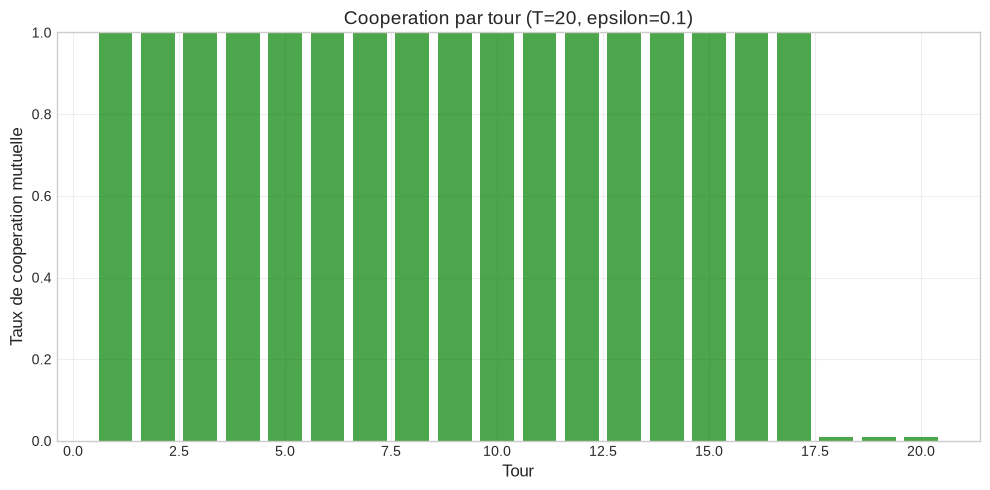

In [8]:
# Simulation du DP fini avec reputation

def simulate_pd_with_reputation(T=20, epsilon=0.1, n_sims=5000):
    """
    Simule le Dilemme du Prisonnier repete avec types.
    
    Strategie heuristique:
    - TFT: Coopere d'abord, puis copie l'adversaire
    - Normal: Coopere tant que l'autre coopere ET tours restants > seuil
              Defecte a la fin ou si l'autre defecte
    """
    payoffs = {
        ('C', 'C'): (3, 3),
        ('C', 'D'): (0, 5),
        ('D', 'C'): (5, 0),
        ('D', 'D'): (1, 1)
    }
    
    results = []
    coop_by_round = np.zeros(T)
    
    for _ in range(n_sims):
        # Tirer les types
        p1_is_tft = np.random.random() < epsilon
        p2_is_tft = np.random.random() < epsilon
        
        # Croyances
        belief_1 = epsilon  # Croyance de P1 que P2 est TFT
        belief_2 = epsilon  # Croyance de P2 que P1 est TFT
        
        gains = [0, 0]
        history_1 = []  # Actions de P1
        history_2 = []  # Actions de P2
        
        for t in range(T):
            remaining = T - t
            
            # Decision de P1
            if p1_is_tft:
                # TFT
                if not history_2:
                    a1 = 'C'
                else:
                    a1 = history_2[-1]
            else:
                # Normal: heuristique
                if remaining > 3 and (not history_2 or history_2[-1] == 'C'):
                    a1 = 'C'  # Coopere pour maintenir reputation
                else:
                    a1 = 'D'  # Defecte a la fin
            
            # Decision de P2 (symetrique)
            if p2_is_tft:
                if not history_1:
                    a2 = 'C'
                else:
                    a2 = history_1[-1]
            else:
                if remaining > 3 and (not history_1 or history_1[-1] == 'C'):
                    a2 = 'C'
                else:
                    a2 = 'D'
            
            # Gains
            p1, p2 = payoffs[(a1, a2)]
            gains[0] += p1
            gains[1] += p2
            
            # Enregistrer
            history_1.append(a1)
            history_2.append(a2)
            
            if a1 == 'C' and a2 == 'C':
                coop_by_round[t] += 1
        
        results.append(gains)
    
    results = np.array(results)
    coop_by_round /= n_sims
    
    print(f"\nSimulation: T={T}, epsilon={epsilon}, {n_sims} parties")
    print("="*50)
    print(f"  Gain moyen P1: {results[:, 0].mean():.2f}")
    print(f"  Gain moyen P2: {results[:, 1].mean():.2f}")
    print(f"  Reference (D,D) tout le temps: {T}")
    print(f"  Reference (C,C) tout le temps: {T * 3}")
    
    # Visualisation
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(range(1, T+1), coop_by_round, color='green', alpha=0.7)
    ax.set_xlabel('Tour', fontsize=12)
    ax.set_ylabel('Taux de cooperation mutuelle', fontsize=12)
    ax.set_title(f'Cooperation par tour (T={T}, epsilon={epsilon})', fontsize=14)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return results, coop_by_round

results, coop = simulate_pd_with_reputation(T=20, epsilon=0.1)

## 5. Equilibre Bayesien Parfait

### 5.1 Definition

Un **Equilibre Bayesien Parfait (PBE)** est un profil de stratégies ET un système de croyances tel que :

1. **Consistance séquentielle** : Les croyances sont derivees par Bayes quand c'est possible
2. **Rationalite séquentielle** : A chaque information set, le joueur maximise son gain espere etant données ses croyances

### 5.2 Relation avec autres concepts

```
    PBE
     |
     v
    SPE (info parfaite)
     |
     v
   Nash
```

### Équilibre bayésien parfait (PBE)

Un PBE comprend un profil de stratégies $\sigma_i(t_i,h)$, dépendant du type et de l'historique, et un système de croyances $\mu(t\mid h)$ sur les types à chaque ensemble d'information. Les stratégies sont séquentiellement rationnelles étant donné ces croyances :

$$\sigma_i(t_i,h) \in \arg\max E[u_i\mid t_i,h,\mu].$$

Les croyances sont cohérentes avec les stratégies par la règle de Bayes lorsque celle-ci s'applique :

$$\mu(t\mid h)=\frac{P(h\mid t)P(t)}{P(h)}.$$

Dans un jeu de signal, la nature tire un type $H$ ou $L$, observé par l'émetteur qui choisit un signal $m_1$ ou $m_2$ ; le récepteur observe le signal et choisit une action. Le PBE spécifie les stratégies de chaque type de l'émetteur, la réponse à chaque signal et les croyances du récepteur. Un équilibre **séparateur** utilise des signaux différents selon le type ; en **pooling**, les types utilisent le même signal et les croyances sur le chemin restent les croyances initiales ; un équilibre **semi-séparateur** distingue certains types seulement.


## 6. Exercices

### Exercice 1: Beer-Quiche Game

Jeu de signaling classique:
- Nature: type S (Strong, p=0.9) ou W (Weak, p=0.1)
- S prefere Beer, W prefere Quiche
- R observe le petit-dejeuner et decide: Fight ou Not
- R prefere Fight si W, Not si S

Trouvez tous les PBE.

### Exercice 2: Reputation avec Plusieurs Adversaires Simultanes

Modifiez le modèle de Kreps-Wilson pour un monopole faisant face a N entrants simultanement (pas sequentiellement).

### Exercice 3: Cheap Talk avec Verification

Reprenez le modèle Crawford-Sobel mais avec une probabilite p que le message soit verifie après coup. Comment cela affecte-t-il la quantite d'information transmise?

In [9]:
# Espace pour vos solutions

# Exercice 1: Beer-Quiche
def solve_beer_quiche():
    """Resout le jeu Beer-Quiche."""
    # Exercice: Analyser le jeu Beer-Quiche
    # 1. Identifier les types (Strong/Weak) et leurs probabilites
    # 2. Lister les strategies possibles pour chaque type
    # 3. Determiner les PBE (Perfect Bayesian Equilibria) potentiels:
    #    - Pooling sur Beer? Pooling sur Quiche?
    #    - Separateur: S->Beer, W->Quiche?
    # 4. Verifier les croyances hors equilibre et la coherence
    #
    # Indice: P(Strong)=0.9, P(Weak)=0.1
    # Strong prefere Beer, Weak prefere Quiche
    # Le Receiver choisit Fight ou Not apres avoir observe le signal
    print("Exercice a completer")
    return None

solve_beer_quiche()

Exercice a completer


***

## Exercice 4 : Paradoxe de la chaîne de magasins

**Objectifs** :

1. Modeliser le paradoxe de Selten
2. Analyser l'effet de reputation avec types imperfaits
3. Comparer equilibrium théorique vs comportement observe

**Contexte** : Une chaîne de magasins fait face a N entrants potentiels. L'incumbent peut etre "rationnel" (accommoder) ou "dur" (toujours combattre). Les entrants ne connaissent pas le type exact.

**Questions** :

1. Quel est l'equilibre avec information complete ?
2. Comment la possibilite d'etre "dur" change-t-elle l'equilibre ?
3. Combien de periodes l'incumbent rationnel maintient-il sa reputation ?


In [10]:
# Exercice : Chain Store Paradox avec reputation
import numpy as np

# Exercice: Definir les parametres du jeu
# N_ENTRANTS = 20
# P_HARD = 0.3  # Probabilite a priori que l'incumbent soit "dur"
#
# PAYOFFS = {
#     'hard': {'Fight': 0, 'Accommodate': -1},
#     'rational': {'Fight': -2, 'Accommodate': 1},
#     'entrant': {'Enter_if_fight': -2, 'Enter_if_accommodate': 2, 'Stay': 0}
# }

# Exercice: Implementer la mise a jour des croyances (Bayes)
# def update_belief(prior, action):
#     # Si l'incumbent combat, augmenter P(hard)
#     # P(hard | Fight) = P(Fight | hard) * P(hard) / P(Fight)
#     ...

# Exercice: Simuler le jeu avec mise a jour des croyances
# def simulate_chain_store(p_hard, n_entrants):
#     ...

# Exercice: Analyser l'effet de la reputation
# for p in [0.1, 0.3, 0.5]:
#     result = simulate_chain_store(p, N_ENTRANTS)
#     print(f"P(hard)={p}: {result['fights']} combats sur {N_ENTRANTS}")
print("Exercice a completer")

Exercice a completer


### Exercice 5 : Repeated Prisoner's Dilemma avec Reputation

Simulez un Dilemme du Prisonnier repete sur 10 tours entre un joueur avec stratégie de reputation
(Tit-for-Tat) et un joueur opportuniste (best response myope).

- **Étape 1** : Implementer Tit-for-Tat et Best-Response-Myope
- **Étape 2** : Simuler 10 tours et calculer les gains cumules
- **Étape 3** : Analyser si la reputation (TFT) est un avantage ou un cout

*Indice* : En finitude connue, backward induction predit toujours defect. La reputation change-t-elle cela ?

In [11]:
# Exercice 5 : Repeated Prisoner's Dilemma avec Reputation
# TODO etudiant : implementer TFT vs BR-Myope sur 10 tours
# Etape 1 : definir les deux strategies
# Etape 2 : simulation
# Etape 3 : comparaison des gains cumules
def simulate_tft_vs_myopic(payoff_matrix: dict, n_rounds: int = 10) -> dict:
    return {"tft_payoff": 0, "myopic_payoff": 0, "history": []}  # TODO etudiant

print("Exercice a completer")

Exercice a completer


## 7. Resume

| Concept | Description |
|---------|-------------|
| **Reputation** | Image basee sur les actions passees |
| **Cheap Talk** | Communication gratuite et non-verifiable |
| **Type behavioural** | Type engage dans un comportement (ex: TFT, Fou) |
| **Imitation stratégique** | Type normal imitant le type behavioural |
| **PBE** | Equilibre avec croyances et stratégies coherentes |

### Points cles

- Une **petite incertitude** peut avoir de **grands effets**
- La reputation permet de rendre credibles des menaces autrement vides
- Le **cheap talk** est limite mais peut transmettre de l'information partielle
- L'**equilibre bayesien parfait** formalise la coherence croyances-stratégies

### Prochaine étape

**Notebook 13 : CFR et Information Imparfaite** - Algorithmes pour resoudre les grands jeux a information imparfaite (poker, etc.).

## Resume et perspectives

Ce notebook a montre comment l'introduction d'une incertitude même infime sur les types des joueurs transforme radicalement les predictions de la théorie des jeux. Le modèle de Kreps-Wilson a resolu le paradoxe de la chaîne de magasins : avec une probabilite $\epsilon$ d'un type "Fou", le monopole rationnel peut imiter ce type pour batir une reputation de durete, dissuadant les entrants et, pouvant modifier les incitations par rapport a l'information complete. La simulation simplifiee de la section 3 ne le met pas en evidence : le cout de construction de reputation y domine, le type Normal y finit a -7.00, sous la reference +10 d'information complete (section 3). Pour le Dilemme du Prisonnier fini, le calcul heuristique utilise 5% de probabilite d'un type Tit-for-Tat et donne 16 tours de cooperation et une amelioration de 160% ; ces valeurs illustrent la regle choisie, sans resoudre un equilibre KMRW.

L'analyse du cheap talk, en revanche, a revele les limites de la communication non-couteuse : le modèle Crawford-Sobel montre que plus le biais entre expert et decideur augmente, moins d'information est transmise, jusqu'a l'equilibre "babbling" ou la parole est totalement vide de contenu. L'equilibre bayesien parfait (PBE) a fourni le cadre formel unificateur, combinant stratégies optimales et mise a jour coherente des croyances via la règle de Bayes, et distinguant les equilibres separateurs, pooling et semi-separateurs selon la capacite des signaux a reveler l'information privee.

Les concepts de reputation et de signaling presentes ici eclairent de nombreuses situations reelles : construction de credibilite en negociation internationale, certifications et diplomes comme signaux couteux sur le marche du travail, et communication stratégique entre entreprises. Le notebook suivant poursuit cette exploration de l'information imparfaite sous l'angle algorithmique, avec la méthode CFR (Counterfactual Regret Minimization) qui permet de calculer des equilibres de Nash dans des jeux a très grande espace d'etats comme le poker.



### References academiques

- Kreps, D.M. & Wilson, R. (1982). Reputation and Imperfect Information. Journal of Economic Theory 27(2):253-279.
- Kreps, D.M., Milgrom, P., Roberts, J. & Wilson, R. (1982). Rational Cooperation in the Finitely Repeated Prisoners' Dilemma. Journal of Economic Theory 27(2):245-252. -- le resultat KMRW de la section 4 (Modele 1, "ROW Might Play Tit-for-Tat") : une infime probabilite qu'un joueur soit engage sur la strategie Tit-for-Tat suffit a soutenir la cooperation dans le Dilemme du Prisonnier fini.
- Milgrom, P. & Roberts, J. (1982). Predation, Reputation, and Entry Deterrence. Journal of Economic Theory 27(2):280-312.
- Crawford, V.P. & Sobel, J. (1982). Strategic Information Transmission. Econometrica 50(6):1431-1451.
- Fudenberg, D. & Levine, D. K. (1989). *Reputation and Equilibrium Selection in Games with a Patient Player.* Econometrica 57(4): 759-778. -- formalisation des conditions sous lesquelles la reputation suffit a selectionner un equilibre dans les jeux repetes (chain store paradox). **Mapping** : §3 Kreps-Wilson (selection d'equilibre par la reputation du patient player).
- Aumann, R. J. (1976). *Agreeing to Disagree.* Annals of Statistics 4(6): 1236-1239. -- resultat fondateur : desaccord de posteriors possible meme sous **common priors** et **common knowledge of rationality** (condition différente de que la simple connaissance commune des posteriors, qui peut etre triviale). **Prealable epistemique** : §3 Kreps-Wilson + §5 PBE -- la reputation necessite la mise a jour bayesienne des croyances sous hypothese de Harsanyi types.
- Aumann, R. J. (1987). *Correlated Equilibrium as an Expression of Bayesian Rationality.* Econometrica 55(1): 1-18. -- formalisation des equilibres correles comme generalisation des equilibres de Nash bayesiens, fondation de l'analyse des croyances partagees. **Prealable epistemique** : §5 PBE (les croyances correlees sous-tendent l'equilibre bayesien parfait).
- Bonanno, G. (2015). *Game Theory* (open access textbook, 165 solved exercises). arXiv:1512.06808 [math.HO], CC BY-NC-ND 4.0. -- manuel de reference. **Mapping direct** : Ch. 9 §9.1-9.3 *Common knowledge of rationality* (prealable epistemique de la reputation) + Ch. 13 §13.1-13.4 *Incomplete Information: Static Games* (transformation de Harsanyi, types, BNE -- fondation du chain store) + Ch. 14 §14.1-14.2 *Incomplete Information: Dynamic Games* (revelation sequentielle des types, mecanisme du chain store) + Ch. 15 §15.1-15.3 *Type-space approach* (Harsanyi types, generalisation).
